# AO-Photonic Spectrograph Performance Simulator
### From residual wavefronts to radial-velocity information

**Research question.** How do seeing, residual AO wavefront error, tip-tilt jitter,
and photonic-lantern mode count affect fibre coupling, spectral SNR, and RV precision?

This **NIRPS-like, ANDES-inspired conceptual trade study** connects wave optics to
an observable measurement. Compact photonic inputs can connect AO-corrected focal
planes to stable spectrographs; mode capacity, injection stability, and detector
cost must be considered together. The ELT motivation is high-resolution NIR
spectroscopy; this notebook uses a **3.6 m circular pupil**, not an ELT model.

> This is an independent conceptual study and is not an official ESO instrument model.

All observations below are synthetic. Nothing is fitted to NIRPS, ANDES, OOPAO,
or an optical testbench. [ESO NIRPS design context](https://www.eso.org/sci/facilities/develop/instruments/NIRPS.html),
[ANDES project paper](https://arxiv.org/abs/2407.14601),
and the [technical note](../docs/technical_note.md) explain the scope.

In [1]:
from pathlib import Path
from dataclasses import replace
from IPython.display import display, Markdown, HTML
import json, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from aophoton.config import load_config, parameter_records
from aophoton.pupil import make_pupil
from aophoton.atmosphere import make_ao_residual
from aophoton.propagation import propagate, polychromatic_psf
from aophoton.metrics import rms_wfe_nm, strehl_ratio, marechal_strehl
from aophoton.coupling import gaussian_mode, overlap_efficiency
from aophoton.lantern import mode_basis, ModeProjector
from aophoton.simulation import run_simulation, save_result
from aophoton.detector import simulate_detector
from aophoton.radial_velocity import rv_uncertainty

START = time.perf_counter()
ROOT = Path.cwd() if (Path.cwd() / 'configs/baseline.yaml').exists() else Path.cwd().parent
assert (ROOT / 'configs/baseline.yaml').exists(), 'Run from the project root or notebooks directory.'
FIGURES = ROOT / 'figures'
FIGURES.mkdir(exist_ok=True)
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)
cfg = load_config(ROOT / 'configs/baseline.yaml')
plt.rcParams.update({'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11,
                     'figure.dpi': 115, 'savefig.dpi': 300, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.18,
                     'figure.facecolor': 'white', 'axes.facecolor': '#fcfcfd',
                     'axes.prop_cycle': plt.cycler(color=['#146c94','#e07a3f','#704c9f','#29816b','#bf4b63'])})

def export(fig, name):
    fig.savefig(FIGURES / f'{name}.png', dpi=300, bbox_inches='tight')
    fig.savefig(FIGURES / f'{name}.pdf', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def table(rows, headers):
    import html
    h = '<table><thead><tr>' + ''.join(f'<th style="text-align:left;padding:5px 12px">{html.escape(str(x))}</th>' for x in headers) + '</tr></thead><tbody>'
    for row in rows:
        h += '<tr>' + ''.join(f'<td style="text-align:left;padding:4px 12px">{html.escape(str(x))}</td>' for x in row) + '</tr>'
    display(HTML(h + '</tbody></table>'))

print('Configuration loaded. Fixed seeds and explicit units are used throughout.')

Matplotlib is building the font cache; this may take a moment.


Configuration loaded. Fixed seeds and explicit units are used throughout.


## 1. System overview

Scalar optical fields are propagated coherently at each wavelength. Independent
exposures and wavelengths are combined as **intensities or coupled powers**, never
as a mean complex field. A matched template then connects detected electrons to RV.

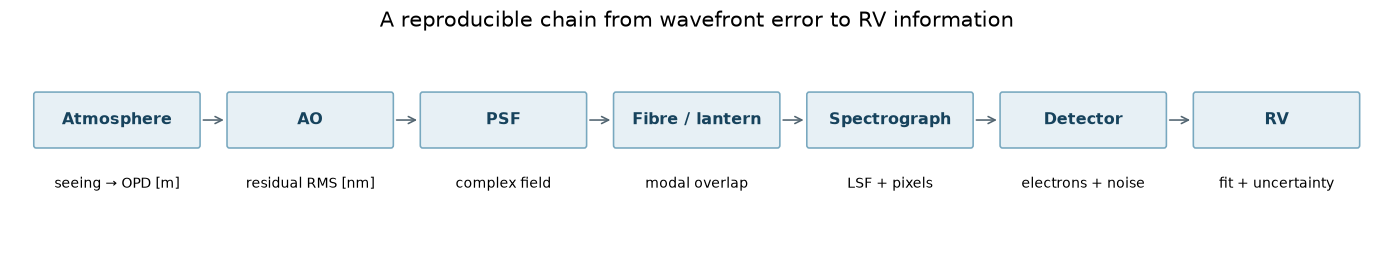

In [2]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(12, 2.1), layout='constrained')
labels = [('Atmosphere','seeing → OPD [m]'), ('AO','residual RMS [nm]'), ('PSF','complex field'),
          ('Fibre / lantern','modal overlap'), ('Spectrograph','LSF + pixels'),
          ('Detector','electrons + noise'), ('RV','fit + uncertainty')]
for i, (title, subtitle) in enumerate(labels):
    x = i * 1.65
    ax.add_patch(FancyBboxPatch((x-0.69,-0.07),1.38,0.38,boxstyle='round,pad=0.02',
                               facecolor='#e7f0f5',edgecolor='#78a8bf'))
    ax.text(x,0.12,title,ha='center',va='center',weight='bold',fontsize=10,color='#17435d')
    ax.text(x, -0.36, subtitle, ha='center', va='center', fontsize=9)
    if i < len(labels)-1:
        ax.annotate('', xy=(x+0.94,0.12), xytext=(x+0.71,0.12), arrowprops=dict(arrowstyle='->',color='#526571'))
ax.set(xlim=(-0.9,10.8), ylim=(-0.8,0.75), title='A reproducible chain from wavefront error to RV information')
ax.axis('off')
export(fig, 'system_overview')

## 2. Baseline and provenance

The three sourced entries are source-inspired **historical design values** (including
NIRPS's historical HAM R=100,000 baseline), not assertions
about current instrument performance. All other settings are assumed or illustrative.
There are **no fitted instrument parameters**. Throughput is a staged budget:
illuminated pupil area × wavelength-dependent coupling × lantern transmission
(if selected) × assumed optics-and-QE throughput. Background is specified after detection.

In [3]:
records = parameter_records(cfg)
table([(r['parameter'], r['value'], r['status']) for r in records], ['Parameter (units in name)', 'Value', 'Provenance'])
(RESULTS / 'parameter_provenance.json').write_text(json.dumps(records, indent=2) + '\n')
t = cfg.telescope
pupil = make_pupil(t.n_pix, t.diameter_m, t.obscuration, t.spider_width_m)
reference = propagate(pupil, np.zeros_like(pupil.amplitude), cfg.ao.wavelength_um, t.pad_factor)

Parameter (units in name),Value,Provenance
seed,2026,illustrative
telescope.diameter_m,3.6,sourced
telescope.obscuration,0.25,assumed
telescope.spider_width_m,0.0,assumed
telescope.n_pix,128,illustrative
telescope.pad_factor,4,illustrative
ao.wavelength_um,1.555,assumed
ao.seeing_arcsec,0.8,assumed
ao.reference_seeing_arcsec,0.8,assumed
ao.residual_wfe_nm,150.0,assumed


## 3. Wavefronts and PSFs

The finite periodic von Kármán screen is piston/tip/tilt removed and scaled to a
specified RMS. This is **scalar AO attenuation**, not a control-loop simulation.
At fixed attenuation, changing seeing scales the residual as
$\sigma_W=\sigma_{W,\mathrm{ref}}(\epsilon/\epsilon_{\mathrm{ref}})^{5/6}$.
The screen has no subharmonics; large-scale atmospheric variance is not recovered.

For small phase variance, the extended Maréchal cross-check is
$S\simeq\exp[-(2\pi\sigma_W/\lambda)^2]$. Measured Strehl comes directly from the
flux-normalized PSF peak. This comparison omits jitter; the later long-exposure
baseline includes it. Large-WFE disagreement is informative, not a failed fit.

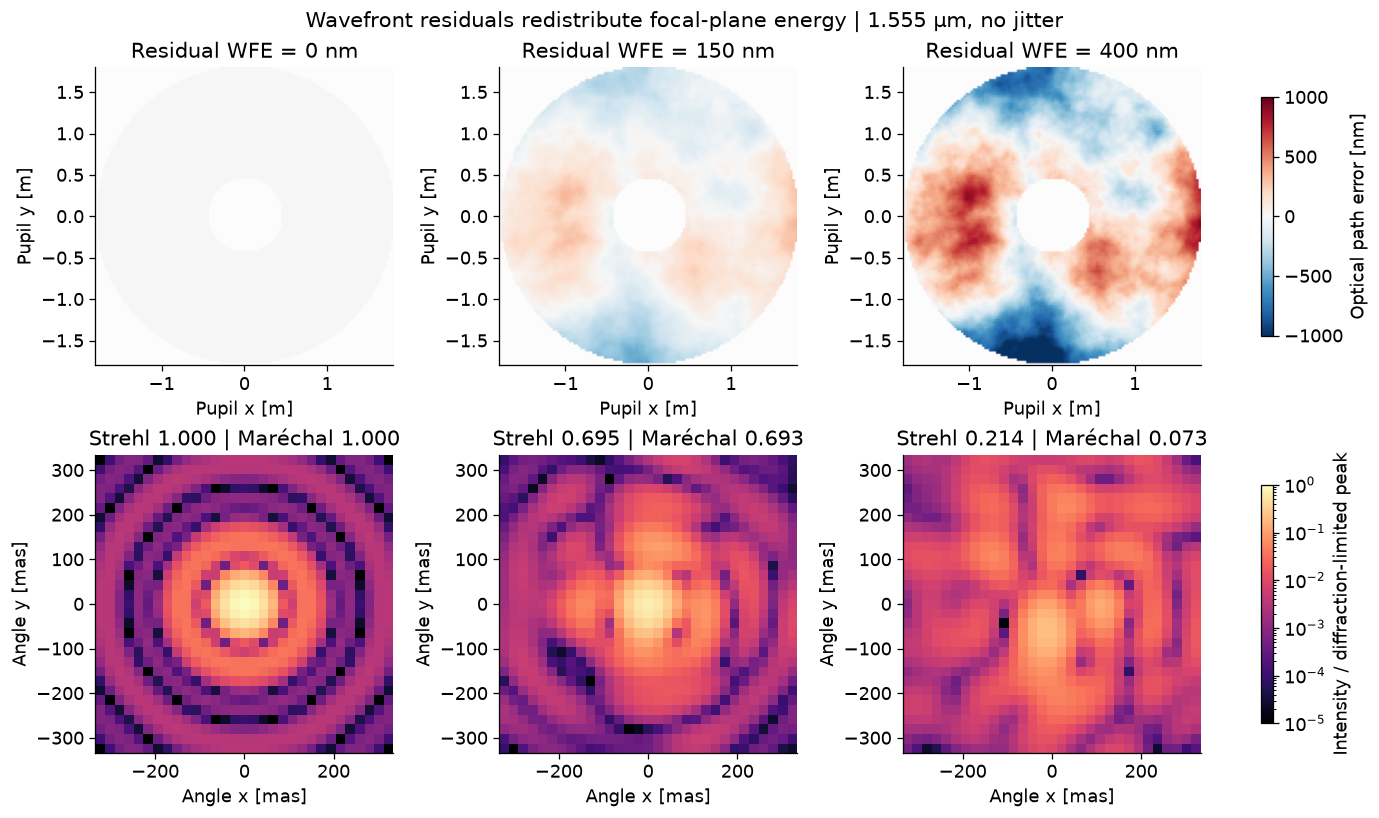

Residual WFE [nm],Measured Strehl,Maréchal
0,1.0000,1.0000
150,0.6947,0.6926
400,0.2135,0.0734


In [4]:
wfe_cases = [0, 150, 400]
case_fields, case_opds, strehl_rows = [], [], []
for wfe in wfe_cases:
    opd = make_ao_residual(pupil, wfe, np.random.default_rng(401))
    focal = propagate(pupil, opd, cfg.ao.wavelength_um, t.pad_factor)
    measured = strehl_ratio(focal.intensity, reference.intensity)
    case_fields.append(focal); case_opds.append(opd)
    strehl_rows.append((wfe, measured, marechal_strehl(wfe, cfg.ao.wavelength_um)))
fig, axes = plt.subplots(2, 3, figsize=(12, 7), layout='constrained')
mask = pupil.amplitude > 0
crop = np.abs(reference.axis_mas) <= 350
angular_extent = [reference.axis_mas[crop][0], reference.axis_mas[crop][-1]] * 2
for i, (wfe, direct, approx) in enumerate(strehl_rows):
    wave = np.where(mask, case_opds[i]*1e9, np.nan)
    imw = axes[0,i].imshow(wave, origin='lower', extent=[-t.diameter_m/2,t.diameter_m/2]*2,
                           cmap='RdBu_r', vmin=-1000, vmax=1000)
    axes[0,i].set(title=f'Residual WFE = {wfe} nm', xlabel='Pupil x [m]', ylabel='Pupil y [m]')
    data = case_fields[i].intensity[np.ix_(crop,crop)] / reference.intensity.max()
    imp = axes[1,i].imshow(data, origin='lower', extent=angular_extent, cmap='magma', norm=LogNorm(1e-5,1))
    axes[1,i].set(title=f'Strehl {direct:.3f} | Maréchal {approx:.3f}', xlabel='Angle x [mas]', ylabel='Angle y [mas]')
    for ax in axes[:,i]: ax.grid(False)
fig.colorbar(imw, ax=axes[0,:], label='Optical path error [nm]', shrink=0.8)
fig.colorbar(imp, ax=axes[1,:], label='Intensity / diffraction-limited peak', shrink=0.8)
fig.suptitle(f'Wavefront residuals redistribute focal-plane energy | {cfg.ao.wavelength_um:.3f} µm, no jitter')
export(fig, 'wavefront_psf')
table([(w, f'{s:.4f}', f'{m:.4f}') for w,s,m in strehl_rows], ['Residual WFE [nm]', 'Measured Strehl', 'Maréchal'])

## 4. Complex-field coupling

The Gaussian fundamental is $E_f\propto\exp[-r^2/w^2]$, with $w=57$ mas the
**1/e field radius** (equivalent angular mode-field diameter 114 mas).
Coupling uses the complex overlap, including phase:

$$\eta=\frac{|\sum E E_f^*|^2}{\sum|E|^2\sum|E_f|^2}.$$

A uniform pixel-area factor cancels. An intensity-only overlap would lose essential
phase information. The mode radius is held fixed in angular units throughout this
small wavelength interval, an assumed achromatic injection relay.

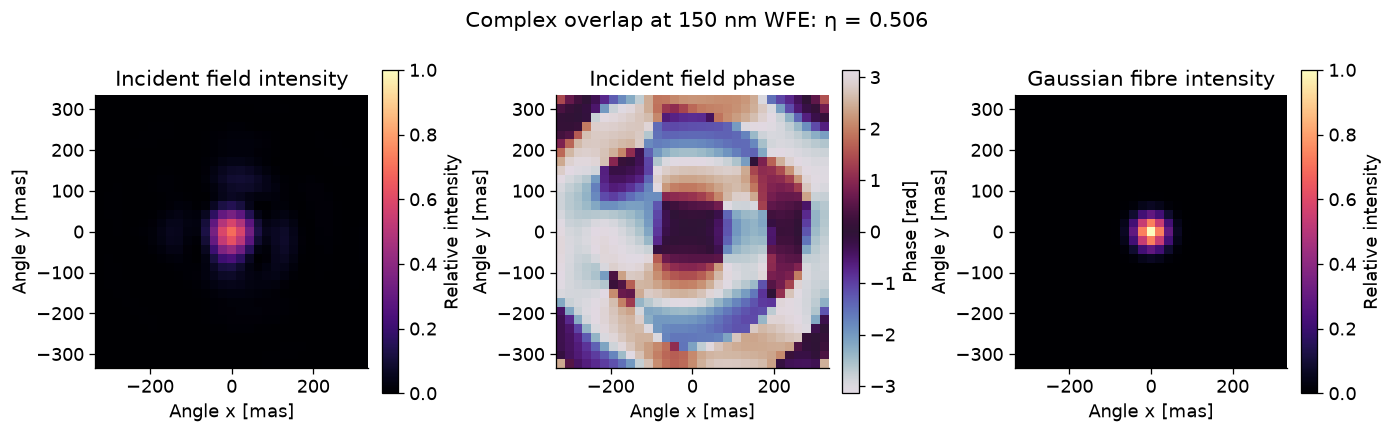

In [5]:
focal = case_fields[1]
mode = gaussian_mode(focal, cfg.fibre.mode_radius_mas)
mode = mode / np.sqrt(np.sum(np.abs(mode)**2))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), layout='constrained')
data_items = [(np.abs(focal.field)**2 / reference.intensity.max(), 'Incident field intensity', 'magma', None),
              (np.angle(focal.field), 'Incident field phase', 'twilight', (-np.pi,np.pi)),
              (np.abs(mode)**2 / np.max(np.abs(mode)**2), 'Gaussian fibre intensity', 'magma', None)]
for ax, (data,title,cmap,limits) in zip(axes,data_items):
    kwargs = dict(vmin=limits[0],vmax=limits[1]) if limits else dict(vmin=0,vmax=1)
    im = ax.imshow(data[np.ix_(crop,crop)], origin='lower',extent=angular_extent,cmap=cmap,**kwargs)
    ax.set(title=title,xlabel='Angle x [mas]',ylabel='Angle y [mas]'); ax.grid(False)
    fig.colorbar(im, ax=ax, label='Phase [rad]' if limits else 'Relative intensity', shrink=0.85)
fig.suptitle(f'Complex overlap at 150 nm WFE: η = {overlap_efficiency(focal.field,mode):.3f}')
export(fig, 'field_overlap')

## 5. Core design map and lantern trade

The sweep uses common random wavefront shapes and pointing draws to compare designs
with lower Monte Carlo scatter. Each cell averages 12 independent realizations;
this is an ensemble without a physical cadence. Jitter means **RMS per axis**.

The few-mode/lantern model projects onto orthonormal Hermite-Gaussian functions,
an ideal parabolic-index guide approximation. Complete mode groups of 1, 3, 6, 10,
and 15 avoid selecting only one orientation in a degenerate group. Port counts refer
to scalar spatial modes with polarization effects omitted. A 90% assumed lantern
transmission follows the projection. This predicts accepted total power, not
individual port illumination, taper losses, or real fibre cutoffs.

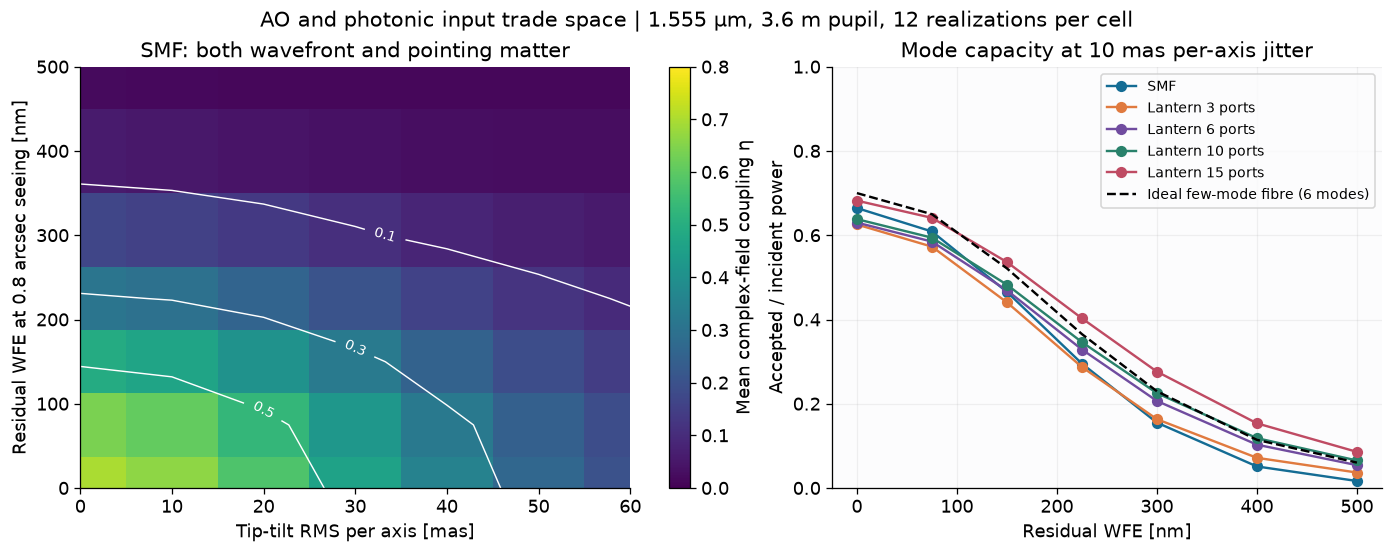

In [6]:
wfe_grid = np.array([0, 75, 150, 225, 300, 400, 500], dtype=float)
jitter_grid = np.array([0, 10, 20, 30, 40, 50, 60], dtype=float)
ports = np.array([1,3,6,10,15])
sweep_frames = 12
basis = mode_basis(reference, cfg.fibre.mode_radius_mas, int(ports.max()))
projector = ModeProjector(basis)  # validate the fixed orthonormal subspace once
unit_opds = [make_ao_residual(pupil, 1.0, np.random.default_rng(610+i)) for i in range(sweep_frames)]
tilt_draws = np.random.default_rng(810).normal(size=(sweep_frames,2))
modal_map = np.zeros((len(wfe_grid), len(jitter_grid), len(basis)))
smf_samples = np.zeros((len(wfe_grid), len(jitter_grid), sweep_frames))
strehl_grid = np.zeros(len(wfe_grid))
for iw, wfe in enumerate(wfe_grid):
    mean_zero_jitter_psf = np.zeros_like(reference.intensity)
    for ij, jitter in enumerate(jitter_grid):
        for iframe, unit_opd in enumerate(unit_opds):
            field = propagate(pupil, unit_opd*wfe, cfg.ao.wavelength_um, t.pad_factor,
                              tuple(tilt_draws[iframe]*jitter))
            powers = projector.powers(field.field)
            modal_map[iw,ij] += powers / sweep_frames
            smf_samples[iw,ij,iframe] = powers[0]
            if ij == 0: mean_zero_jitter_psf += field.intensity / sweep_frames
    strehl_grid[iw] = strehl_ratio(mean_zero_jitter_psf, reference.intensity)
eta_map = modal_map[:,:,0]
eta_sem = smf_samples.std(axis=2,ddof=1)/np.sqrt(sweep_frames)
fig, axes = plt.subplots(1,2,figsize=(12,4.7),layout='constrained')
im = axes[0].pcolormesh(jitter_grid,wfe_grid,eta_map,shading='nearest',cmap='viridis',vmin=0,vmax=0.8)
contours = axes[0].contour(jitter_grid,wfe_grid,eta_map,levels=[0.1,0.3,0.5],colors='white',linewidths=0.9)
axes[0].clabel(contours,fmt='%.1f',fontsize=9)
axes[0].set(xlabel='Tip-tilt RMS per axis [mas]',ylabel='Residual WFE at 0.8 arcsec seeing [nm]',title='SMF: both wavefront and pointing matter')
axes[0].grid(False)
axes[0].set(xlim=(0,60),ylim=(0,500))
fig.colorbar(im,ax=axes[0],label='Mean complex-field coupling η')
for n in ports:
    accepted = modal_map[:,1,:n].sum(axis=1)
    transmission = 1.0 if n == 1 else cfg.fibre.lantern_transmission
    axes[1].plot(wfe_grid,transmission*accepted,'o-',label='SMF' if n==1 else f'Lantern {n} ports')
axes[1].plot(wfe_grid,modal_map[:,1,:6].sum(axis=1),'k--',label='Ideal few-mode fibre (6 modes)')
axes[1].set(xlabel='Residual WFE [nm]',ylabel='Accepted / incident power',ylim=(0,1),title='Mode capacity at 10 mas per-axis jitter')
axes[1].legend(fontsize=9)
fig.suptitle('AO and photonic input trade space | 1.555 µm, 3.6 m pupil, 12 realizations per cell')
export(fig, 'core_design_map')
np.savez_compressed(RESULTS/'design_map.npz',wfe_nm=wfe_grid,jitter_mas=jitter_grid,modal_power=modal_map,
                    smf_sem=eta_sem,strehl=strehl_grid,ports=ports)

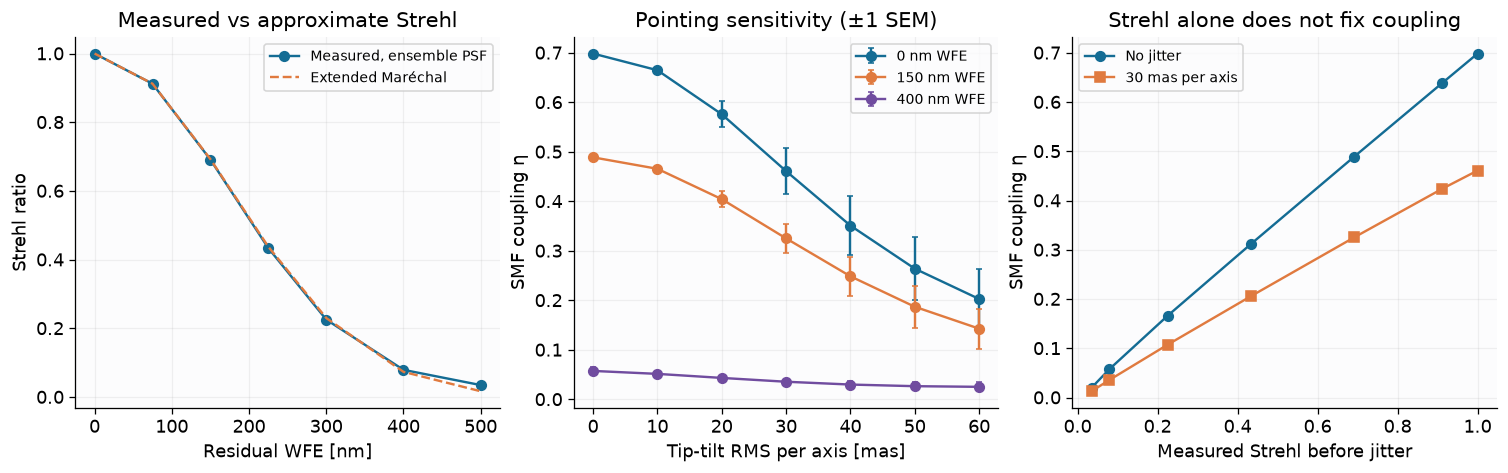

In [7]:
fig, axes = plt.subplots(1,3,figsize=(13,4),layout='constrained')
axes[0].plot(wfe_grid,strehl_grid,'o-',label='Measured, ensemble PSF')
axes[0].plot(wfe_grid,marechal_strehl(wfe_grid,cfg.ao.wavelength_um),'--',label='Extended Maréchal')
axes[0].set(xlabel='Residual WFE [nm]',ylabel='Strehl ratio',title='Measured vs approximate Strehl'); axes[0].legend(fontsize=9)
for iw in [0,2,5]:
    axes[1].errorbar(jitter_grid,eta_map[iw],yerr=eta_sem[iw],marker='o',capsize=2,label=f'{wfe_grid[iw]:.0f} nm WFE')
axes[1].set(xlabel='Tip-tilt RMS per axis [mas]',ylabel='SMF coupling η',title='Pointing sensitivity (±1 SEM)'); axes[1].legend(fontsize=9)
axes[2].plot(strehl_grid,eta_map[:,0],'o-',label='No jitter')
axes[2].plot(strehl_grid,eta_map[:,3],'s-',label='30 mas per axis')
axes[2].set(xlabel='Measured Strehl before jitter',ylabel='SMF coupling η',title='Strehl alone does not fix coupling'); axes[2].legend(fontsize=9)
export(fig,'coupling_sensitivity')

## 6. Wavelength, seeing, and a limited polychromatic PSF

The same optical-path residual produces more phase error at shorter wavelengths.
Seeing below changes residual WFE under the documented fixed-attenuation model;
it is not an additional halo convolution at fixed WFE. The broadband PSF below is
an incoherent equal-photon-weight sum on a common angular grid.

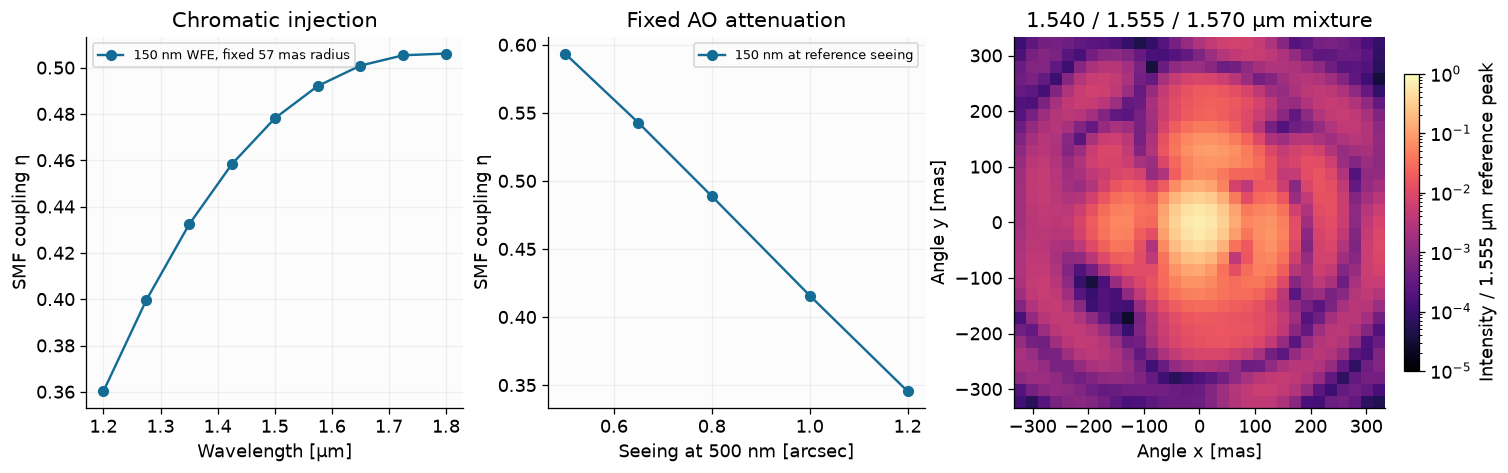

Broadband captured fraction on the common finite grid: 0.99994819


In [8]:
wavelengths = np.linspace(1.2,1.8,9)
seeing_values = np.array([0.5,0.65,0.8,1.0,1.2])
wave_eta, seeing_eta = [], []
for wave in wavelengths:
    samples = [overlap_efficiency((fp:=propagate(pupil,u*150,wave,t.pad_factor)).field,
                                  gaussian_mode(fp,cfg.fibre.mode_radius_mas)) for u in unit_opds]
    wave_eta.append(np.mean(samples))
for seeing in seeing_values:
    scale = (seeing/cfg.ao.reference_seeing_arcsec)**(5/6)
    seeing_eta.append(np.mean([overlap_efficiency(propagate(pupil,u*150*scale,cfg.ao.wavelength_um,t.pad_factor).field,basis[0]) for u in unit_opds]))
broadband = polychromatic_psf(pupil,case_opds[1],[1.54,1.555,1.57],pad_factor=t.pad_factor,axis_mas=reference.axis_mas)
fig,axes=plt.subplots(1,3,figsize=(13,4),layout='constrained')
axes[0].plot(wavelengths,wave_eta,'o-',label='150 nm WFE, fixed 57 mas radius')
axes[0].set(xlabel='Wavelength [µm]',ylabel='SMF coupling η',title='Chromatic injection'); axes[0].legend(fontsize=8)
axes[1].plot(seeing_values,seeing_eta,'o-',label='150 nm at reference seeing')
axes[1].set(xlabel='Seeing at 500 nm [arcsec]',ylabel='SMF coupling η',title='Fixed AO attenuation'); axes[1].legend(fontsize=8)
im=axes[2].imshow(broadband.intensity[np.ix_(crop,crop)]/reference.intensity.max(),origin='lower',extent=angular_extent,cmap='magma',norm=LogNorm(1e-5,1))
axes[2].set(xlabel='Angle x [mas]',ylabel='Angle y [mas]',title='1.540 / 1.555 / 1.570 µm mixture'); axes[2].grid(False)
fig.colorbar(im,ax=axes[2],label='Intensity / 1.555 µm reference peak',shrink=0.8)
export(fig,'wavelength_seeing')
print(f'Broadband captured fraction on the common finite grid: {broadband.intensity.sum():.8f}')

## 7. Synthetic observation

A seeded set of absorption lines is an illustrative stellar template, without a
claimed temperature, metallicity, or observational identity. It is Doppler shifted,
convolved with a Gaussian LSF on log wavelength, and integrated over each detector
pixel. The template extends beyond the output interval to protect RV estimates
from edge effects. The model also imports explicit one-dimensional ASCII/FITS templates.

Poisson source, background and dark counts plus Gaussian read noise are generated
in electrons. Expected background and dark are subtracted without removing their
variance. The incident photon-rate density, continuum, and instrument response are
known exactly in this synthetic example. SNR is **per detector pixel**.

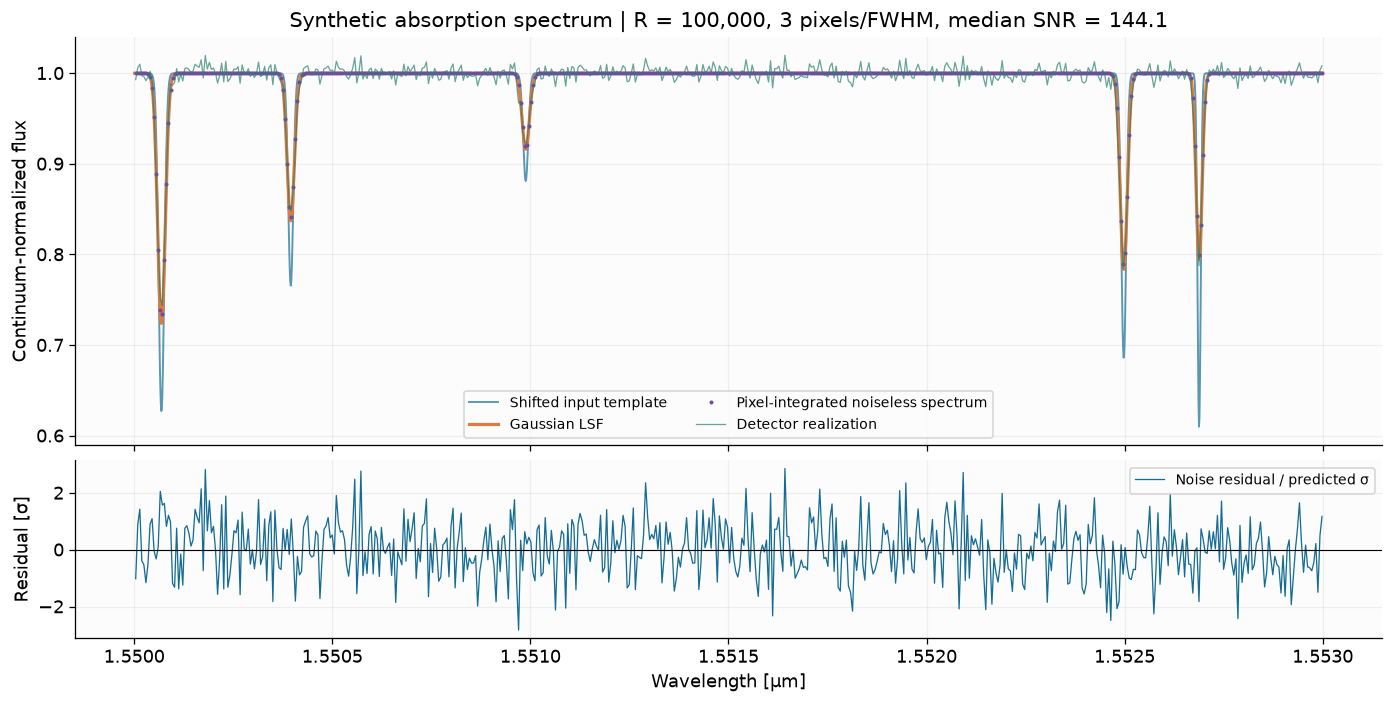

Computed result,Value (units in key)
seed,2026
feed,smf
residual_wfe_nm,150.0000
measured_strehl,0.6598
marechal_without_jitter,0.6926
mean_smf_coupling,0.4711
mean_few_mode_coupling,0.5303
mean_lantern_coupling,0.4772
mean_selected_coupling,0.4711
collecting_area_m2,9.5365


In [9]:
baseline = run_simulation(cfg)
save_result(baseline,RESULTS/'showcase_baseline')
summary = baseline.summary()
forward = baseline.spectral_model.evaluate(cfg.observation.injected_rv_m_s)
model = baseline.spectral_model
det = baseline.detector
select = (model.wavelength_um >= 1.550) & (model.wavelength_um <= 1.553)
highselect = (forward.highres_wavelength_um >= 1.550) & (forward.highres_wavelength_um <= 1.553)
fig,axes=plt.subplots(2,1,figsize=(12,6),layout='constrained',sharex=True,gridspec_kw={'height_ratios':[2.3,1]})
axes[0].plot(forward.highres_wavelength_um[highselect],forward.input_flux[highselect],lw=1.2,alpha=0.7,label='Shifted input template')
axes[0].plot(forward.highres_wavelength_um[highselect],forward.convolved_flux[highselect],lw=2,label='Gaussian LSF')
axes[0].plot(model.wavelength_um[select],forward.normalized_flux[select],'.',ms=3,label='Pixel-integrated noiseless spectrum')
axes[0].plot(model.wavelength_um[select],(det.flux_e/det.continuum_e)[select],lw=0.8,alpha=0.7,label='Detector realization')
axes[0].set(ylabel='Continuum-normalized flux',title=f'Synthetic absorption spectrum | R = {cfg.spectrograph.resolving_power:,.0f}, 3 pixels/FWHM, median SNR = {np.median(det.snr):.1f}')
axes[0].legend(ncol=2,fontsize=9)
axes[1].plot(model.wavelength_um[select],((det.flux_e-det.expected_source_e)/np.sqrt(det.variance_e2))[select],lw=0.8,label='Noise residual / predicted σ')
axes[1].axhline(0,color='black',lw=0.7);axes[1].set(xlabel='Wavelength [µm]',ylabel='Residual [σ]');axes[1].legend(fontsize=9)
export(fig,'synthetic_observation')
table([(key,f'{value:.4f}' if isinstance(value,float) else value) for key,value in summary.items() if key not in ['disclaimer','validation']],['Computed result','Value (units in key)'])

## 8. RV injection and recovery

The fit receives the data and model, **not the injected velocity**. A coarse grid
locates a minimum, followed by continuous $\chi^2$ minimization using the same LSF
and pixel integration. The local uncertainty is
$\sigma_v=[\sum_i(\partial\mu_i/\partial v)^2/\mathrm{Var}_i]^{-1/2}$,
with source, background, dark, and read variance. This is a conditional statistical
forecast with exact template, continuum, and wavelength calibration. It excludes
systematic RV floors. [Bouchy, Pepe & Queloz (2001)](https://doi.org/10.1051/0004-6361:20010730)
provide the photon-information basis.

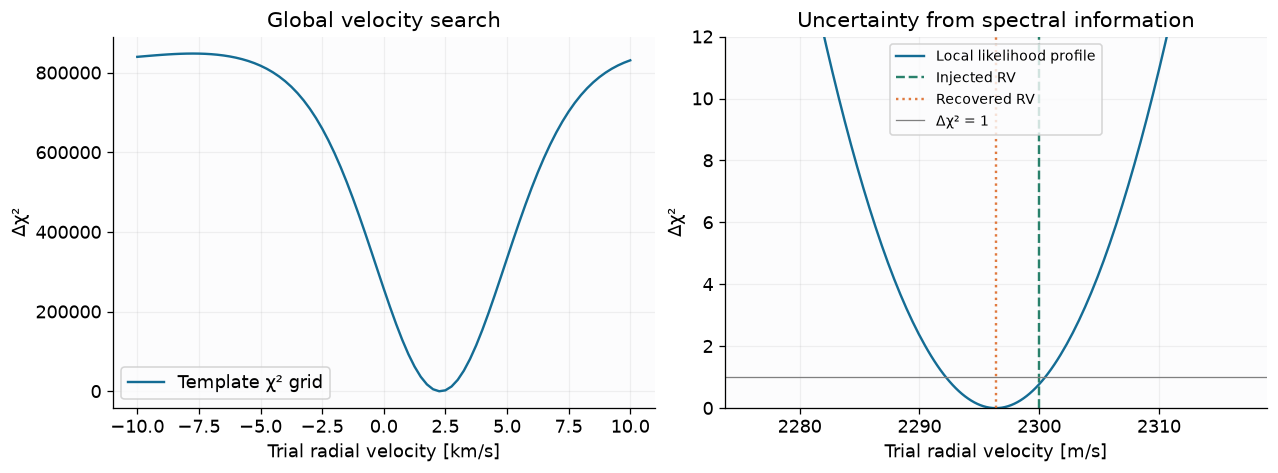

Injected **2300.00 m/s**; recovered **2296.37 ± 4.12 m/s** (conditional 1σ). Recovery error (“bias” for this realization): **-3.63 m/s**. A single noisy recovery does not estimate an ensemble bias.

In [10]:
rv = baseline.rv
local_v = np.linspace(rv.rv_m_s-5*rv.uncertainty_m_s,rv.rv_m_s+5*rv.uncertainty_m_s,161)
local_chi2 = np.array([np.sum((det.flux_e-det.continuum_e*model(v))**2/det.variance_e2) for v in local_v])
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
axes[0].plot(rv.grid_velocities_m_s/1000,rv.chi2-rv.minimum_chi2,label='Template χ² grid')
axes[0].set(xlabel='Trial radial velocity [km/s]',ylabel='Δχ²',title='Global velocity search'); axes[0].legend()
axes[1].plot(local_v,local_chi2-rv.minimum_chi2,label='Local likelihood profile')
axes[1].axvline(cfg.observation.injected_rv_m_s,color='#29816b',ls='--',label='Injected RV')
axes[1].axvline(rv.rv_m_s,color='#e07a3f',ls=':',label='Recovered RV')
axes[1].axhline(1,color='gray',lw=0.8,label='Δχ² = 1')
axes[1].set(xlabel='Trial radial velocity [m/s]',ylabel='Δχ²',ylim=(0,12),title='Uncertainty from spectral information');axes[1].legend(fontsize=9)
export(fig,'rv_recovery')
display(Markdown(f'Injected **{cfg.observation.injected_rv_m_s:.2f} m/s**; recovered **{rv.rv_m_s:.2f} ± {rv.uncertainty_m_s:.2f} m/s** (conditional 1σ). '
                 f'Recovery error (“bias” for this realization): **{summary["recovery_bias_m_s"]:+.2f} m/s**. A single noisy recovery does not estimate an ensemble bias.'))

## 9. Coupling, brightness, and the detector cost of more ports

For this narrow band the comparison below uses the 1.555 µm mean coupling as a
constant approximation. Every port is read as an independent extraction channel;
all channels have the same LSF and total source counts are conserved when summed.
The six-mode direct fibre uses one extraction channel, an optimistic comparison
that omits mode-dependent line-shape changes. Close rankings remain subject to the finite optical ensemble and assumed mode basis.
The faint case reduces incident
photon rate by 100; it is an illustrative detector-noise sensitivity study.

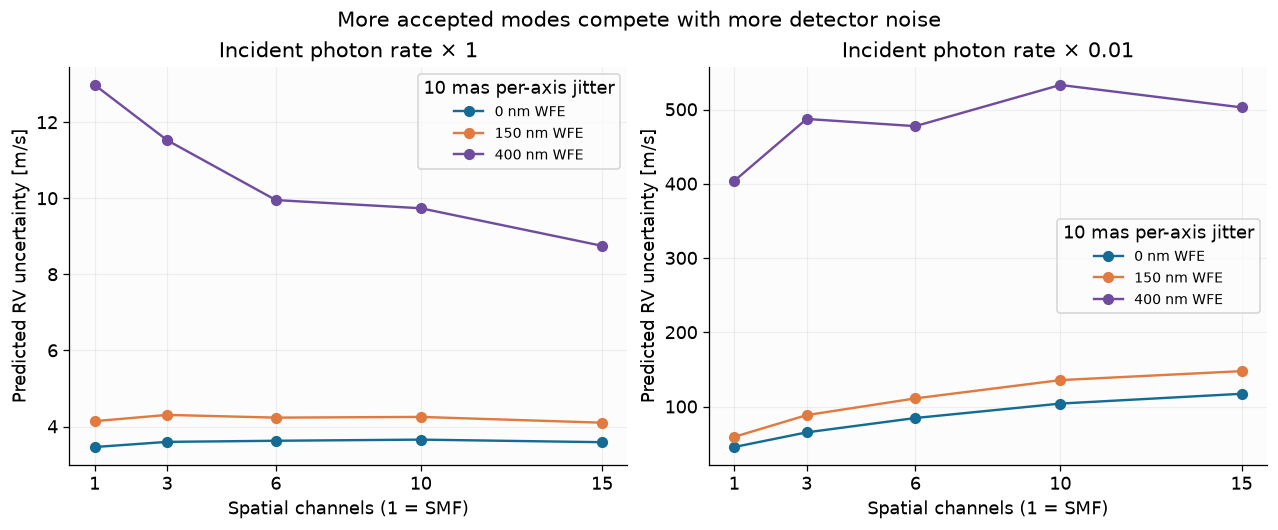

In [11]:
trade_rows=[]
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for ax,brightness in zip(axes,[1.0,0.01]):
    for iw in [0,2,5]:
        uncertainties=[]
        for n in ports:
            eta = modal_map[iw,1,:n].sum()*(1 if n==1 else cfg.fibre.lantern_transmission)
            dcfg = replace(cfg.detector,continuum_photons_s_m2_um=cfg.detector.continuum_photons_s_m2_um*brightness)
            d = simulate_detector(model(cfg.observation.injected_rv_m_s),model.pixel_width_um,dcfg,
                                  collecting_area_m2=baseline.optics.collecting_area_m2,coupling=eta,
                                  throughput=cfg.spectrograph.throughput,n_channels=int(n),noisy=False)
            sigma = rv_uncertainty(model,cfg.observation.injected_rv_m_s,d.variance_e2,d.continuum_e)
            uncertainties.append(sigma)
            trade_rows.append(dict(brightness_scale=brightness,wfe_nm=float(wfe_grid[iw]),ports=int(n),
                                   coupling=float(eta),median_snr=float(np.median(d.snr)),rv_sigma_m_s=sigma))
        ax.plot(ports,uncertainties,'o-',label=f'{wfe_grid[iw]:.0f} nm WFE')
    ax.set(xlabel='Spatial channels (1 = SMF)',ylabel='Predicted RV uncertainty [m/s]',
           title=f'Incident photon rate × {brightness:g}',xticks=ports)
    ax.legend(title='10 mas per-axis jitter',fontsize=9)
fig.suptitle('More accepted modes compete with more detector noise')
export(fig,'rv_port_trade')
_ = (RESULTS/'port_trade.json').write_text(json.dumps(trade_rows,indent=2)+'\n')

## 10. Engineering conclusions and limitations

The conclusions below are generated from the saved sweeps. They are predictions
of this reduced model, not measured instrument performance. The automated tests
separately cover Airy diffraction, FFT energy, small-error Strehl, overlap bounds,
mode-space conservation, ensemble aberration trends, noise statistics, seed
reproducibility, and zero-noise/Monte Carlo RV recovery.

In [12]:
eta_good,eta_bad = eta_map[0,0],eta_map[-1,0]
eta_center,eta_jitter = eta_map[2,0],eta_map[2,4]
bright_rows = [r for r in trade_rows if r['brightness_scale']==1 and r['wfe_nm']==400]
faint_rows = [r for r in trade_rows if r['brightness_scale']==0.01 and r['wfe_nm']==400]
bright_smf,bright_pl = bright_rows[0],bright_rows[-1]
faint_smf,faint_pl = faint_rows[0],faint_rows[-1]
conclusions=[
 f'At zero jitter, increasing residual WFE from 0 to 500 nm changes mean SMF coupling from {eta_good:.3f} to {eta_bad:.3f}; wavefront quality sets the photon budget.',
 f'At 150 nm WFE, increasing per-axis jitter from 0 to 40 mas changes SMF coupling from {eta_center:.3f} to {eta_jitter:.3f}; injection stability remains important even at fixed AO residual.',
 f'At 400 nm WFE / 10 mas jitter, replacing the SMF with a 15-port lantern changes forecast σRV from {bright_smf["rv_sigma_m_s"]:.2f} to {bright_pl["rv_sigma_m_s"]:.2f} m/s at baseline brightness, but from {faint_smf["rv_sigma_m_s"]:.2f} to {faint_pl["rv_sigma_m_s"]:.2f} m/s at 1/100 brightness. Under the assumed insertion loss and extraction noise, detector costs can reverse the throughput advantage.'
]
display(Markdown('\n\n'.join(f'**{i+1}.** {c}' for i,c in enumerate(conclusions))))
elapsed = time.perf_counter()-START
metrics=dict(baseline=summary,conclusions=conclusions,strehl_cases=strehl_rows,
             sweep_frames=sweep_frames,maximum_coupling_sem=float(eta_sem.max()),
             wavelength_um=wavelengths.tolist(),wavelength_coupling=wave_eta,
             seeing_arcsec=seeing_values.tolist(),seeing_coupling=seeing_eta,
             notebook_runtime_s=elapsed)
(RESULTS/'showcase_metrics.json').write_text(json.dumps(metrics,indent=2,allow_nan=False)+'\n')
print(f'Notebook numerical work: {elapsed:.1f} s. Figures exported as 300 dpi PNG and vector PDF to figures/.')

**1.** At zero jitter, increasing residual WFE from 0 to 500 nm changes mean SMF coupling from 0.699 to 0.020; wavefront quality sets the photon budget.

**2.** At 150 nm WFE, increasing per-axis jitter from 0 to 40 mas changes SMF coupling from 0.489 to 0.249; injection stability remains important even at fixed AO residual.

**3.** At 400 nm WFE / 10 mas jitter, replacing the SMF with a 15-port lantern changes forecast σRV from 12.98 to 8.75 m/s at baseline brightness, but from 403.84 to 502.86 m/s at 1/100 brightness. Under the assumed insertion loss and extraction noise, detector costs can reverse the throughput advantage.

Notebook numerical work: 15.6 s. Figures exported as 300 dpi PNG and vector PDF to figures/.


**Physical limitations.** Scalar polarization; finite periodic turbulence with no
subharmonics; imposed per-screen RMS and uniform AO attenuation; no temporal servo,
WFS, deformable mirror, scintillation, anisoplanatism, segmented ELT pupil, or chromatic
non-common-path aberrations. HG modes are guide approximations with no real NA/core
cutoffs, taper geometry, mode-dependent loss, modal noise or port cross-talk. The
spectrograph has a stationary Gaussian LSF and exact template/continuum/wavelength
solution; no tellurics, stellar activity, wavelength drift, bad pixels, persistence,
saturation, echelle layout, extraction covariance, or absolute flux calibration.
Independent phase frames omit finite-exposure speckle/throughput variance. The Fisher
uncertainty is conditional and does not include these omitted terms.

**Next experimental step.** On a narrowband photonic-chip injection bench, calibrate
plate scale and Gaussian mode size, scan focal-plane offsets, inject known pupil
aberrations, and measure SMF and total lantern throughput with reference photometry.
Compare normalized overlap curves before fitting a transition-loss parameter; retain
independent settings for validation. This is aligned with the
[ESO photonic-chip testbench topic](https://www.eso.org/sci/activities/fellowships-and-studentships/engstudentfellow/photonic_chips.html).
A later public NIRPS spectrum can test wavelength sampling and RV extraction,
with archive identifier and access date recorded; it alone cannot validate this AO
coupling model. **No observational validation or OOPAO comparison has been performed.**

See [technical note](../docs/technical_note.md), [verified references](../docs/references.md),
and [public-template procedure](../docs/public_data.md). All code cells can be rerun
from a fresh kernel; no downloads are needed for this notebook.